# Stage 1 — ForestNet: download, Q1 EDA and leakage checks

**Project:** Classifying Deforestation Drivers from Satellite Imagery (image-only)

**Th purpose and process of the notebook**
1. Downloads ForestNet from the official Stanford link and records what was downloaded.
2. Takes an inventory of the files: CSV columns, image types, and whether near-infrared (NIR) is present.
3. EDA: class balance (4 merged classes *and* the fine-grained labels), year, geography, images per event, image quality (cloud proxy), loss-region size.
4. Leakage checks on the **official** split: same event in two splits, overlapping image footprints, near-duplicate images, columns unavailable at prediction time.
5. Saves a frozen split manifest + empty experiment log that every later stage will use.



**Run on:** Google Colab (using CPU)

## 0. Setup and fixed seeds
`SEED` is used for every random step (sampling images to plot, etc.) so re-running gives identical outputs.
`USE_DRIVE=True` saves the dataset to the Google Drive so prevent the need of re-downloading the data for every session.

In [ ]:
import os, sys, random, json, hashlib, pickle, zipfile, time, platform
from pathlib import Path

SEED = 42
random.seed(SEED)

import numpy as np
np.random.seed(SEED)

USE_DRIVE = True          # set False on Kaggle
IN_COLAB = "google.colab" in sys.modules

if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/forestnet_project")
elif Path("/kaggle/working").exists():
    BASE = Path("/kaggle/working/forestnet_project")
else:
    BASE = Path("./forestnet_project")

DATA_DIR = BASE / "data"
OUT_DIR = BASE / "outputs" / "stage1"
for d in (DATA_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Project folder:", BASE)
print("Python", platform.python_version(), "| numpy", np.__version__)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/forestnet_project
Python 3.13.18 | numpy 2.1.3


In [ ]:
# Extra libraries: imagehash for near-duplicate detection, shapely for loss polygons.
# (pandas, matplotlib, sklearn, PIL are preinstalled on Colab/Kaggle.)
!pip -q install imagehash shapely

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import imagehash
from sklearn.neighbors import BallTree

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 1. Download ForestNet
Source: https://stanfordmlgroup.github.io/projects/forestnet (licence stated there: **CC BY 4.0**).


In [ ]:
URL = "http://download.cs.stanford.edu/deep/ForestNetDataset.zip"
ZIP_PATH = DATA_DIR / "ForestNetDataset.zip"

if not ZIP_PATH.exists():
    !wget -q --show-progress -O "{ZIP_PATH}" "{URL}"
else:
    print("Zip already downloaded — skipping.")

def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

zip_size_mb = ZIP_PATH.stat().st_size / 1e6
zip_hash = sha256(ZIP_PATH)
print(f"Zip size: {zip_size_mb:.1f} MB")
print("SHA-256:", zip_hash)

/content/drive/MyDr 100%[===================>]   3.13G  5.07MB/s    in 10m 38s 
Zip size: 3360.1 MB
SHA-256: a94c6a372ba85c91336718527d552560b2e1818e6d98a51e342b60bd6b231698


In [ ]:
# Unzip once. We then search for the folder that contains train.csv instead of
# assuming a path, because we have not yet seen the archive's layout.
EXTRACT_DIR = DATA_DIR / "raw"
if not EXTRACT_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)

csvs = sorted(EXTRACT_DIR.rglob("*.csv"))
print("CSV files found:")
for c in csvs:
    print("  ", c.relative_to(EXTRACT_DIR))
ROOT = next(c.parent for c in csvs if c.name == "train.csv")
print("\nDataset root:", ROOT)

CSV files found:
   deep/downloads/ForestNetDataset/test.csv
   deep/downloads/ForestNetDataset/train.csv
   deep/downloads/ForestNetDataset/val.csv

Dataset root: /content/drive/MyDrive/forestnet_project/data/raw/deep/downloads/ForestNetDataset


## 2. Inventory :what is actually in the dataset?
We look before we assume. This answers two open questions from your plan:
**(a)** what the CSV columns are, **(b)** whether a near-infrared band is included.

In [ ]:
splits = {}
for name in ("train", "val", "test"):
    df_s = pd.read_csv(ROOT / f"{name}.csv")
    df_s["split"] = name
    splits[name] = df_s
    print(f"{name}: {len(df_s)} rows | columns: {list(df_s.columns)}")

df = pd.concat(splits.values(), ignore_index=True)
display(df.head())

train: 1616 rows | columns: ['label', 'merged_label', 'latitude', 'longitude', 'year', 'example_path', 'split']
val: 473 rows | columns: ['label', 'merged_label', 'latitude', 'longitude', 'year', 'example_path', 'split']
test: 668 rows | columns: ['label', 'merged_label', 'latitude', 'longitude', 'year', 'example_path', 'split']


,label,merged_label,latitude,longitude,year,example_path,split
0,Timber plantation,Plantation,4.430849,96.101634,2014,examples/4.430849118860583_96.1016343478138,train
1,Other,Other,1.332341,109.374229,2012,examples/1.3323406178609702_109.37422873130464,train
2,Grassland shrubland,Grassland shrubland,-1.720266,115.006996,2016,examples/-1.720266384577504_115.00699582064485,train
3,Small-scale agriculture,Smallholder agriculture,-2.248346,104.135786,2011,examples/-2.248346072674411_104.1357857482906,train
4,Other large-scale plantations,Plantation,-2.100800,113.022376,2008,examples/-2.100800102991412_113.0223763234016,train


In [ ]:
# Find which column is the 4-class target and which is the fine-grained label,
# by counting unique values rather than guessing names.
for col in df.columns:
    if df[col].dtype == object and col not in ("split",):
        n = df[col].nunique()
        print(f"{col!r}: {n} unique values" + (f" -> {sorted(df[col].unique())}" if n <= 15 else ""))

'label': 12 unique values -> ['Fish pond', 'Grassland shrubland', 'Logging', 'Mining', 'Oil palm plantation', 'Other', 'Other large-scale plantations', 'Secondary forest', 'Small-scale agriculture', 'Small-scale mixed plantation', 'Small-scale oil palm plantation', 'Timber plantation']
'merged_label': 4 unique values -> ['Grassland shrubland', 'Other', 'Plantation', 'Smallholder agriculture']
'example_path': 2757 unique values


In [ ]:
# >>> CHECK the printout above, then set these two names if they differ. <<<
TARGET_COL = "merged_label"     # expected: the 4 driver classes
FINE_COL = "label"              # expected: the original fine-grained labels
PATH_COL = "example_path"       # expected: folder of one event
assert df[TARGET_COL].nunique() == 4, "TARGET_COL does not have 4 classes — check column names above."

In [ ]:
# Walk one event folder to see its structure.
example_dir = ROOT / df.loc[0, PATH_COL]
for p in sorted(example_dir.rglob("*")):
    if p.is_file():
        print(p.relative_to(example_dir), f"({p.stat().st_size/1e3:.1f} kB)")

auxiliary/gfc.npy (220.6 kB)
auxiliary/ncep.npy (0.8 kB)
auxiliary/osm.json (0.9 kB)
auxiliary/peat.json (0.0 kB)
auxiliary/srtm.npy (2645.5 kB)
forest_loss_region.pkl (0.3 kB)
images/infrared/2015_01_18_cloud_0.npy (661.5 kB)
images/infrared/2015_06_27_cloud_2469.npy (661.5 kB)
images/infrared/2016_02_22_cloud_0.npy (661.5 kB)
images/infrared/2016_07_31_cloud_0.npy (661.5 kB)
images/infrared/2017_03_12_cloud_144.npy (661.5 kB)
images/infrared/2017_06_16_cloud_0.npy (661.5 kB)
images/infrared/2017_08_19_cloud_0.npy (661.5 kB)
images/infrared/2017_10_22_cloud_0.npy (661.5 kB)
images/infrared/2018_06_03_cloud_0.npy (661.5 kB)
images/infrared/composite.npy (661.5 kB)
images/visible/2015_01_18_cloud_0.png (166.2 kB)
images/visible/2015_06_27_cloud_2469.png (161.9 kB)
images/visible/2016_02_22_cloud_0.png (131.5 kB)
images/visible/2016_07_31_cloud_0.png (158.9 kB)
images/visible/2017_03_12_cloud_144.png (145.0 kB)
images/visible/2017_06_16_cloud_0.png (153.3 kB)
images/visible/2017_08_19_cl

In [ ]:
# Inventory across ALL events: count files per sub-folder type and extension.
def inventory(event_dir: Path):
    files = [p for p in event_dir.rglob("*") if p.is_file()]
    rel = [p.relative_to(event_dir) for p in files]
    return {
        "n_files": len(files),
        "n_visible_png": sum(1 for r in rel if "visible" in r.parts and r.suffix == ".png"),
        "n_infrared": sum(1 for r in rel if "infrared" in r.parts),
        "has_composite": any(r.stem == "composite" and "visible" in r.parts for r in rel),
        "has_loss_polygon": any(r.suffix == ".pkl" for r in rel),
        "has_auxiliary": any("auxiliary" in r.parts for r in rel),
    }

t0 = time.time()
inv = pd.DataFrame([inventory(ROOT / p) for p in df[PATH_COL]])
df = pd.concat([df, inv], axis=1)
df["n_single_scenes"] = df["n_visible_png"] - df["has_composite"].astype(int)
print(f"Inventory took {time.time()-t0:.0f}s")
display(df[inv.columns.tolist() + ["n_single_scenes"]].describe(include="all").T)

Inventory took 56s


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
n_files,2757.0,NaN,NaN,NaN,13.328981,5.713358,8.0,10.0,12.0,16.0,52.0
n_visible_png,2757.0,NaN,NaN,NaN,3.66449,2.856679,1.0,2.0,3.0,5.0,23.0
n_infrared,2757.0,NaN,NaN,NaN,3.66449,2.856679,1.0,2.0,3.0,5.0,23.0
has_composite,2757,1,True,2757,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_loss_polygon,2757,1,True,2757,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_auxiliary,2757,1,True,2757,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_single_scenes,2757.0,NaN,NaN,NaN,2.66449,2.856679,0.0,1.0,2.0,4.0,22.0


In [ ]:
# Near-infrared check: open the infrared files of one event (if any) and print shape / dtype / range.
ir_files = sorted(p for p in (ROOT / df.loc[0, PATH_COL]).rglob("*") if p.is_file() and "infrared" in p.parts)
print("Infrared files in first event:", [f.name for f in ir_files][:5])
if ir_files:
    a = np.load(ir_files[0]) if ir_files[0].suffix == ".npy" else np.array(Image.open(ir_files[0]))
    print("shape", a.shape, "| dtype", a.dtype, "| min", a.min(), "| max", a.max())
    # The paper/GEO-Bench describe 6 Landsat bands (RGB + NIR, SWIR1, SWIR2).
    # Channel order and scaling must be confirmed here BEFORE computing NDVI in Stage 2:
    # NDVI = (NIR - Red) / (NIR + Red) is only valid if NIR and Red are on the same scale.
vis = np.array(Image.open(ROOT / df.loc[0, PATH_COL] / "images" / "visible" / "composite.png"))
print("Visible composite: shape", vis.shape, "| dtype", vis.dtype, "| min", vis.min(), "| max", vis.max())
HAS_NIR = bool(df["n_infrared"].gt(0).all())
print("\nNIR present for every event:", HAS_NIR)

Infrared files in first event: ['2015_01_18_cloud_0.npy', '2015_06_27_cloud_2469.npy', '2016_02_22_cloud_0.npy', '2016_07_31_cloud_0.npy', '2017_03_12_cloud_144.npy']
shape (332, 332, 3) | dtype uint16 | min 5 | max 143
Visible composite: shape (332, 332, 3) | dtype uint8 | min 0 | max 98

NIR present for every event: True


## 3. Class balance : 4 driver classes and fine-grained labels


Event counts per class and split:


split,train,val,test,All
merged_label,,,,
Grassland shrubland,143,45,77,265
Other,231,70,106,407
Plantation,686,218,269,1173
Smallholder agriculture,556,140,216,912
All,1616,473,668,2757


Proportions within each split:


split,train,val,test
merged_label,,,
Grassland shrubland,0.088,0.095,0.115
Other,0.143,0.148,0.159
Plantation,0.425,0.461,0.403
Smallholder agriculture,0.344,0.296,0.323


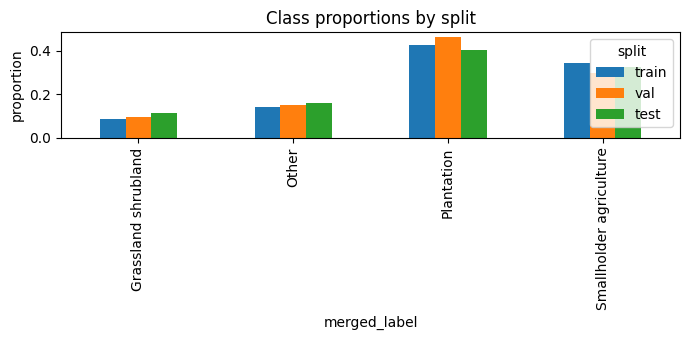

In [ ]:
counts = pd.crosstab(df[TARGET_COL], df["split"], margins=True)[["train", "val", "test", "All"]]
props = pd.crosstab(df[TARGET_COL], df["split"], normalize="columns").round(3)[["train", "val", "test"]]
print("Event counts per class and split:"); display(counts)
print("Proportions within each split:"); display(props)

fig, ax = plt.subplots(figsize=(7, 3.5))
props.plot.bar(ax=ax); ax.set_ylabel("proportion"); ax.set_title("Class proportions by split")
plt.tight_layout(); plt.savefig(OUT_DIR / "class_balance.png", dpi=150); plt.show()

In [ ]:
fine = pd.crosstab([df[TARGET_COL], df[FINE_COL]], df["split"], margins=True)
display(fine)
fine.to_csv(OUT_DIR / "fine_label_counts.csv")

split                                                    test  train  val   All
merged_label            label                                                  
Grassland shrubland     Grassland shrubland                77    143   45   265
Other                   Fish pond                          14     24    7    45
                        Logging                            16     39    5    60
                        Mining                             21     48   21    90
                        Other                              28     49   16    93
                        Secondary forest                   27     71   21   119
Plantation              Oil palm plantation               138    337  124   599
                        Other large-scale plantations      44    118   25   187
                        Timber plantation                  87    231   69   387
Smallholder agriculture Small-scale agriculture           140    355   81   576
                        Small-scale mixed plantation       42    119   31   192
                        Small-scale oil palm plantation    34     82   28   144
All                                                       668   1616  473  2757

## 4. Year and geography
If some classes come from different years or regions, a model could learn "where/when" instead of "what".
The map also gives a first visual sense of whether splits are geographically mixed.

merged_label,Grassland shrubland,Other,Plantation,Smallholder agriculture
year,,,,
2001,0,14,37,27
2002,0,13,46,34
2003,0,14,38,32
2004,0,16,51,64
2005,0,12,71,62
2006,0,19,77,52
2007,0,13,99,63
2008,0,13,109,64
2009,0,14,95,76


split,test,train,val
year,,,
2001,19,46,13
2002,16,55,22
2003,13,41,30
2004,30,78,23
2005,32,87,26
2006,29,87,32
2007,42,97,36
2008,45,112,29
2009,45,112,28


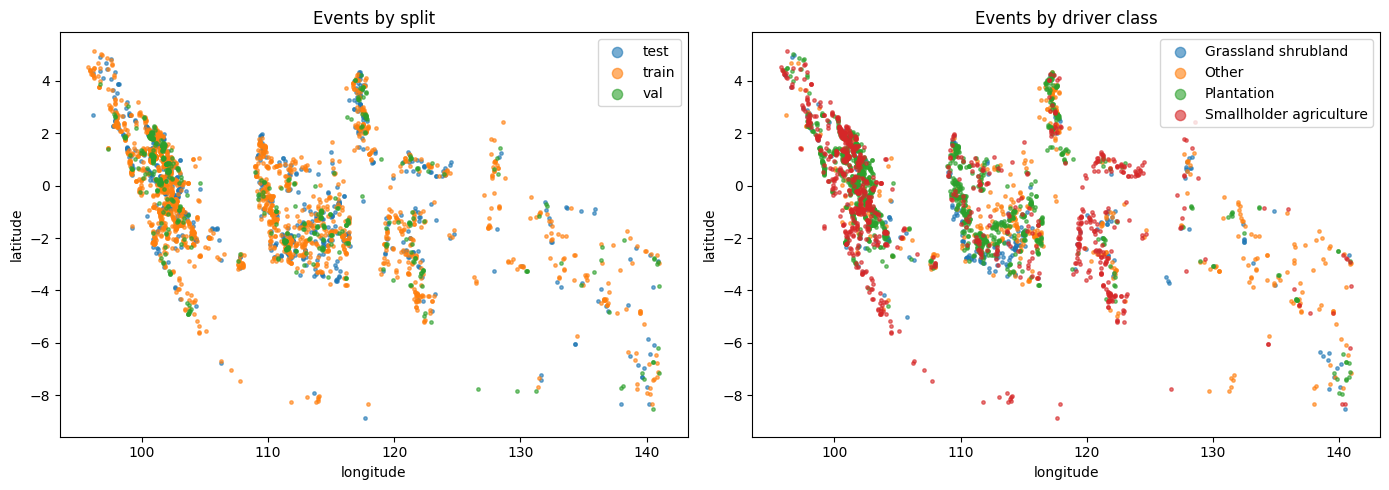

In [ ]:
if "year" in df.columns:
    display(pd.crosstab(df["year"], df[TARGET_COL]))
    display(pd.crosstab(df["year"], df["split"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (col, title) in zip(axes, [("split", "Events by split"), (TARGET_COL, "Events by driver class")]):
    for val, g in df.groupby(col):
        ax.scatter(g["longitude"], g["latitude"], s=6, alpha=0.6, label=val)
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title(title); ax.legend(markerscale=3)
plt.tight_layout(); plt.savefig(OUT_DIR / "map_split_class.png", dpi=150); plt.show()

## 5. Images per event, image quality and loss-region size
- **Single scenes per event:** how many extra images we have for scene data augmentation.
- **Cloud/haze proxy:** fraction of very bright, low-saturation pixels in the composite. This is a *rough proxy*,
  not a cloud mask — check the gallery below to see whether it matches what you see by eye before relying on it.
- **Loss-region area:** size of the forest-loss polygon (in pixels²). Small regions may be harder to classify.

In [ ]:
def cloud_proxy(img_rgb, bright=200, max_spread=25):
    """Fraction of pixels that are bright AND grey-ish (R,G,B close together) — typical of cloud/haze."""
    x = img_rgb[..., :3].astype(np.int16)
    bright_mask = x.min(axis=-1) >= bright
    grey_mask = (x.max(axis=-1) - x.min(axis=-1)) <= max_spread
    return float((bright_mask & grey_mask).mean())

def loss_area(event_dir):
    pkls = list(event_dir.rglob("*.pkl"))
    if not pkls:
        return np.nan, None
    with open(pkls[0], "rb") as f:
        poly = pickle.load(f)
    return float(getattr(poly, "area", np.nan)), getattr(poly, "bounds", None)

rows = []
for p in df[PATH_COL]:
    comp = np.array(Image.open(ROOT / p / "images" / "visible" / "composite.png").convert("RGB"))
    area, bounds = loss_area(ROOT / p)
    rows.append({"img_h": comp.shape[0], "img_w": comp.shape[1],
                 "cloud_proxy": cloud_proxy(comp), "loss_area_px2": area, "poly_bounds": bounds})
q = pd.DataFrame(rows)
df = pd.concat([df, q], axis=1)

print("Image sizes:", df.groupby(["img_h", "img_w"]).size().to_dict())
print("Example polygon bounds (to confirm they are in pixel coordinates):", df["poly_bounds"].dropna().iloc[:3].tolist())
display(df.groupby(TARGET_COL)[["n_single_scenes", "cloud_proxy", "loss_area_px2"]].describe().T)

/tmp/ipykernel_1587/869986376.py:13: UserWarning: Unpickling a shapely <2.0 geometry object. Please save the pickle again as this compatibility may be removed in a future version of shapely.
  poly = pickle.load(f)


Image sizes: {(332, 332): 2757}
Example polygon bounds (to confirm they are in pixel coordinates): [(163.68939741287613, 162.2686925945687, 169.70822276718295, 170.29952282868325), (147.20853091615717, 140.54045068132692, 189.20009086208108, 184.55909533117082), (58.54013880814891, 84.32795037813679, 266.4529460879974, 270.3791051270518)]


merged_label           Grassland shrubland         Other    Plantation  Smallholder agriculture
n_single_scenes count           265.000000    407.000000  1.173000e+03             9.120000e+02
                mean              2.800000      2.476658  2.434783e+00             3.004386e+00
                std               3.045364      2.959300  2.533439e+00             3.104118e+00
                min               0.000000      0.000000  0.000000e+00             0.000000e+00
                25%               1.000000      0.000000  1.000000e+00             1.000000e+00
                50%               2.000000      2.000000  2.000000e+00             2.000000e+00
                75%               4.000000      3.000000  3.000000e+00             4.000000e+00
                max              20.000000     17.000000  2.100000e+01             2.200000e+01
cloud_proxy     count           265.000000    407.000000  1.173000e+03             9.120000e+02
                mean              0.000003      0.000004  2.861723e-07             4.277573e-07
                std               0.000034      0.000028  2.307751e-06             5.300608e-06
                min               0.000000      0.000000  0.000000e+00             0.000000e+00
                25%               0.000000      0.000000  0.000000e+00             0.000000e+00
                50%               0.000000      0.000000  0.000000e+00             0.000000e+00
                75%               0.000000      0.000000  0.000000e+00             0.000000e+00
                max               0.000544      0.000490  4.536217e-05             1.179416e-04
loss_area_px2   count           265.000000    407.000000  1.173000e+03             9.120000e+02
                mean           7618.722266    997.131143  7.674405e+03             1.852617e+03
                std           14217.454991   3091.987682  1.368445e+04             5.382056e+03
                min               7.993609      7.993605  7.993615e+00             7.993603e+00
                25%             499.734871     12.019573  6.318288e+02             5.197095e+01
                50%            1427.050101     47.965179  2.471847e+03             5.717580e+02
                75%            7816.765403    727.489188  8.259926e+03             1.187410e+03
                max           91403.327122  38266.289737  1.108673e+05             8.523875e+04

In [ ]:
# 5b. Cloud cover from single-scene file names (replaces the brightness proxy)
import re
def scene_clouds(event_dir):
    return [int(m.group(1)) for p in (event_dir / "images" / "visible").glob("*.png")
            if (m := re.search(r"cloud_(\d+)", p.stem))]

cl = [scene_clouds(ROOT / p) for p in df[PATH_COL]]
df["n_scenes_cloudfree"] = [sum(v == 0 for v in c) for c in cl]
df["pct_scenes_cloudy"] = [np.mean([v > 0 for v in c]) if c else np.nan for c in cl]
display(df.groupby(TARGET_COL)[["n_single_scenes", "n_scenes_cloudfree", "pct_scenes_cloudy"]]
        .describe().round(2).T)
print("Events with composite only (no single scenes):", int((df["n_single_scenes"] == 0).sum()))

merged_label              Grassland shrubland   Other  Plantation  Smallholder agriculture
n_single_scenes    count               265.00  407.00     1173.00                   912.00
                   mean                  2.80    2.48        2.43                     3.00
                   std                   3.05    2.96        2.53                     3.10
                   min                   0.00    0.00        0.00                     0.00
                   25%                   1.00    0.00        1.00                     1.00
                   50%                   2.00    2.00        2.00                     2.00
                   75%                   4.00    3.00        3.00                     4.00
                   max                  20.00   17.00       21.00                    22.00
n_scenes_cloudfree count               265.00  407.00     1173.00                   912.00
                   mean                  0.97    0.86        0.91                     1.32
                   std                   1.45    1.46        1.32                     1.83
                   min                   0.00    0.00        0.00                     0.00
                   25%                   0.00    0.00        0.00                     0.00
                   50%                   0.00    0.00        0.00                     1.00
                   75%                   1.00    1.00        1.00                     2.00
                   max                   7.00   12.00       12.00                    17.00
pct_scenes_cloudy  count               213.00  295.00      946.00                   753.00
                   mean                  0.67    0.67        0.63                     0.55
                   std                   0.35    0.37        0.38                     0.38
                   min                   0.00    0.00        0.00                     0.00
                   25%                   0.50    0.46        0.33                     0.25
                   50%                   0.67    0.75        0.67                     0.56
                   75%                   1.00    1.00        1.00                     1.00
                   max                   1.00    1.00        1.00                     1.00

Events with composite only (no single scenes): 550


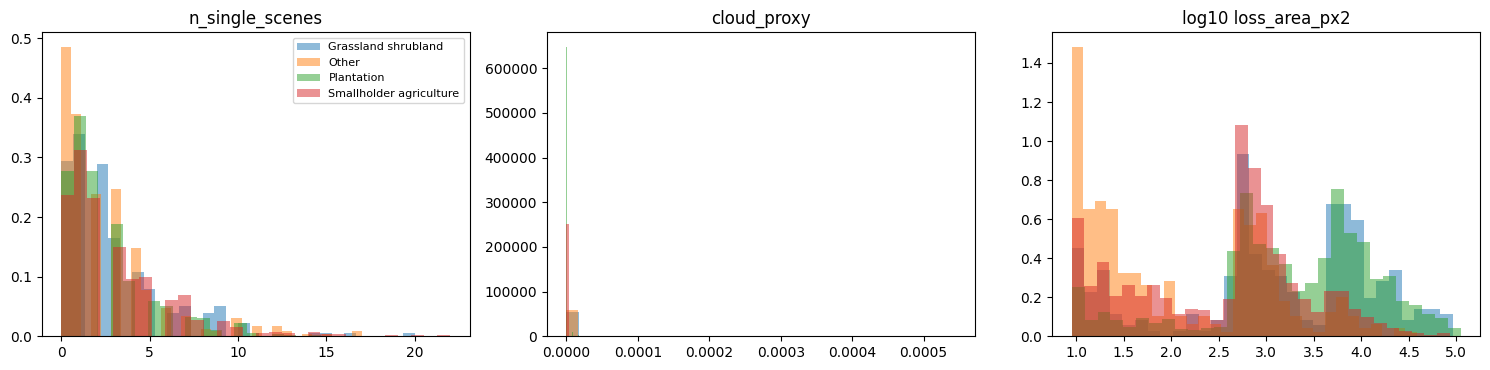

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, logx in zip(axes, ["n_single_scenes", "cloud_proxy", "loss_area_px2"], [False, False, True]):
    for c, g in df.groupby(TARGET_COL):
        vals = g[col].dropna()
        ax.hist(np.log10(vals + 1) if logx else vals, bins=30, alpha=0.5, label=c, density=True)
    ax.set_title(("log10 " if logx else "") + col)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "quality_distributions.png", dpi=150); plt.show()

### Image gallery


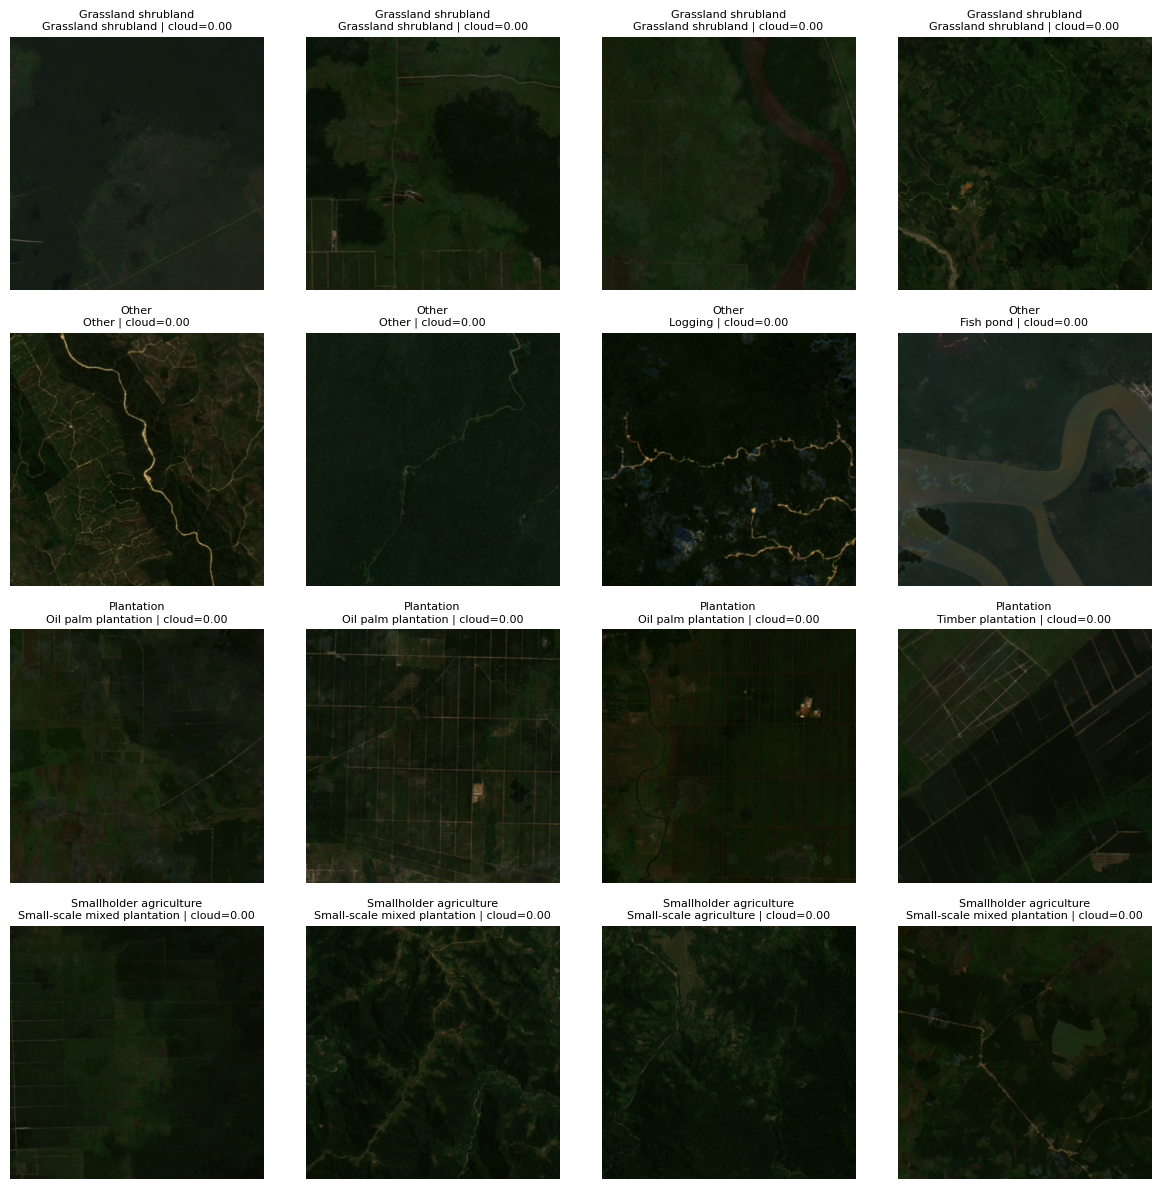

In [ ]:
rng = np.random.default_rng(SEED)
classes = sorted(df[TARGET_COL].unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(12, 3 * len(classes)))
for i, c in enumerate(classes):
    pool = df[(df["split"] == "train") & (df[TARGET_COL] == c)]
    for j, idx in enumerate(rng.choice(pool.index, 4, replace=False)):
        r = df.loc[idx]
        axes[i, j].imshow(Image.open(ROOT / r[PATH_COL] / "images" / "visible" / "composite.png"))
        axes[i, j].set_title(f"{c}\n{r[FINE_COL]} | cloud={r['cloud_proxy']:.2f}", fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "gallery_train.png", dpi=120); plt.show()

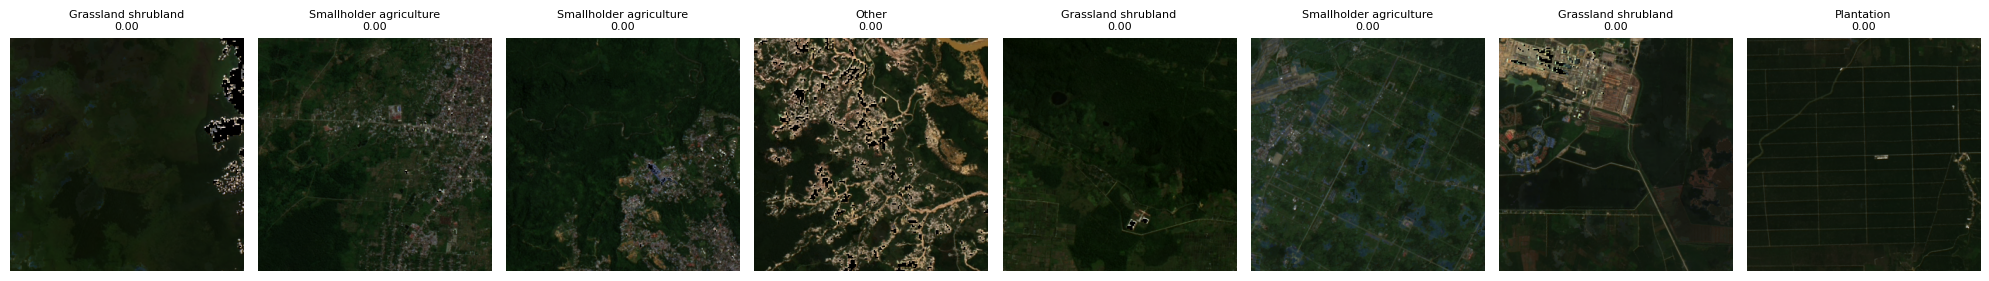

In [ ]:
# Highest cloud-proxy composites (train only) — does the proxy actually find cloudy images?
worst = df[df["split"] == "train"].nlargest(8, "cloud_proxy")
fig, axes = plt.subplots(1, 8, figsize=(20, 3))
for ax, (_, r) in zip(axes, worst.iterrows()):
    ax.imshow(Image.open(ROOT / r[PATH_COL] / "images" / "visible" / "composite.png"))
    ax.set_title(f"{r[TARGET_COL]}\n{r['cloud_proxy']:.2f}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

### Per-class colour statistics (train only)
Mean and std of each RGB channel per class. If classes already differ strongly in plain colour,
the classical baseline will be competitive — (might be useful evidence for the predictions in the next stages.
The overall train mean/std is saved for normalisation in later stages.

In [ ]:
def rgb_stats(path):
    x = np.array(Image.open(ROOT / path / "images" / "visible" / "composite.png").convert("RGB")).astype(np.float32) / 255
    return x.reshape(-1, 3).mean(0), x.reshape(-1, 3).std(0)

tr = df[df["split"] == "train"]
stats = np.array([np.concatenate(rgb_stats(p)) for p in tr[PATH_COL]])
stat_df = pd.DataFrame(stats, columns=["mean_R", "mean_G", "mean_B", "std_R", "std_G", "std_B"], index=tr.index)
stat_df[TARGET_COL] = tr[TARGET_COL]
display(stat_df.groupby(TARGET_COL).mean().round(3))

train_norm = {"mean": stats[:, :3].mean(0).round(4).tolist(), "std": stats[:, 3:].mean(0).round(4).tolist()}
print("Train RGB normalisation (composite):", train_norm)

,mean_R,mean_G,mean_B,std_R,std_G,std_B
merged_label,,,,,,
Grassland shrubland,0.078,0.113,0.054,0.033,0.031,0.024
Other,0.084,0.113,0.059,0.051,0.042,0.036
Plantation,0.090,0.120,0.062,0.043,0.035,0.030
Smallholder agriculture,0.083,0.117,0.056,0.036,0.032,0.026


Train RGB normalisation (composite): {'mean': [0.08550000190734863, 0.11729999631643295, 0.05869999900460243], 'std': [0.040699999779462814, 0.0348999984562397, 0.029100000858306885]}


## 6. Leakage checks
The brief asks for explicit checks. We run five:

| # | Check | Why it matters |
|---|---|---|
| L1 | Each event (folder) appears in exactly one split | Composite + single scenes of one event must stay together |
| L2 | Same coordinates in two splits | Same place, maybe different year — near-identical images |
| L3 | **Overlapping image footprints** across splits | Neighbouring events share pixels, so the model could recognise the place instead of the driver |
| L4 | Near-duplicate composite images across splits (perceptual hash) | Catches duplicates that coordinates miss |
| L5 | Columns not available at prediction time | e.g. labels, auxiliary data not used in an image-only model |

### L1 :one event, one split

In [ ]:
dup_paths = df[PATH_COL].duplicated(keep=False)
print("Event folders listed more than once:", int(dup_paths.sum()))
if dup_paths.any():
    display(df[dup_paths].sort_values(PATH_COL)[[PATH_COL, "split", TARGET_COL]])
# Because every image of an event lives inside its own folder, splitting by folder keeps the
# composite and all single scenes of that event in the same split automatically.

Event folders listed more than once: 0


### L2 : identical coordinates across splits

In [ ]:
df["coord_key"] = df["latitude"].round(5).astype(str) + "_" + df["longitude"].round(5).astype(str)
coord_groups = df.groupby("coord_key")["split"].agg(lambda s: sorted(set(s)))
multi_loc = df.groupby("coord_key").size()
print("Locations with >1 event:", int((multi_loc > 1).sum()))
cross = coord_groups[coord_groups.apply(len) > 1]
print("Locations whose events fall in >1 split:", len(cross))
display(cross.head(20))

Locations with >1 event: 1
Locations whose events fall in >1 split: 0


,split
coord_key,


### L3 : overlapping image footprints across splits
Each image is centred on its event. Pixel size is 15 m, so a 332-pixel image covers about
332 × 15 m ≈ 4.98 km per side (we use the image size measured above, not an assumed value).
Two images overlap if their centres are closer than one image-width **both** north–south and east–west.

Also compare against the within-split nearest-neighbour distances: if cross-split neighbours are
as close as within-split ones, the split is effectively random in space (no spatial separation).

In [ ]:
PIXEL_M = 15.0
IMG_PX = int(df["img_w"].mode()[0])
FOOT_KM = IMG_PX * PIXEL_M / 1000
print(f"Footprint ≈ {FOOT_KM:.2f} km per side")

lat = np.radians(df["latitude"].values); lon = np.radians(df["longitude"].values)
coords = np.c_[lat, lon]
EARTH_KM = 6371.0

def nearest_other(query_mask, ref_mask, exclude_self=False):
    tree = BallTree(coords[ref_mask], metric="haversine")
    k = 2 if exclude_self else 1
    d, i = tree.query(coords[query_mask], k=k)
    col = 1 if exclude_self else 0
    ref_idx = np.where(ref_mask)[0][i[:, col]]
    return d[:, col] * EARTH_KM, ref_idx

def box_overlap(i, j, w_km=FOOT_KM):
    dn = abs(df.loc[i, "latitude"] - df.loc[j, "latitude"]) * 111.32
    de = abs(df.loc[i, "longitude"] - df.loc[j, "longitude"]) * 111.32 * np.cos(np.radians(df.loc[i, "latitude"]))
    return (dn < w_km) and (de < w_km)

split_arr = df["split"].values
results, pairs = [], []
for q_split, r_split in [("val", "train"), ("test", "train"), ("test", "val")]:
    qm, rm = split_arr == q_split, split_arr == r_split
    dist, ref = nearest_other(qm, rm)
    q_idx = np.where(qm)[0]
    ov = np.array([box_overlap(a, b) for a, b in zip(q_idx, ref)])
    same = df.loc[q_idx, TARGET_COL].values == df.loc[ref, TARGET_COL].values
    results.append({"query": q_split, "reference": r_split,
                    "median_NN_km": np.median(dist), "n_within_1km": int((dist < 1).sum()),
                    "n_footprint_overlap": int(ov.sum()),
                    "pct_overlap": round(100 * ov.mean(), 1),
                    "same_label_among_overlaps_%": round(100 * same[ov].mean(), 1) if ov.any() else np.nan})
    pairs += [{"query_idx": a, "ref_idx": b, "dist_km": d, "query_split": q_split, "ref_split": r_split,
               "same_label": s} for a, b, d, o, s in zip(q_idx, ref, dist, ov, same) if o]

for s in ("train", "val", "test"):
    m = split_arr == s
    dist, _ = nearest_other(m, m, exclude_self=True)
    results.append({"query": s, "reference": s + " (within)", "median_NN_km": np.median(dist),
                    "n_within_1km": int((dist < 1).sum()), "n_footprint_overlap": np.nan,
                    "pct_overlap": np.nan, "same_label_among_overlaps_%": np.nan})

leak_df = pd.DataFrame(results).round(2)
display(leak_df)
overlap_pairs = pd.DataFrame(pairs)
overlap_pairs.to_csv(OUT_DIR / "cross_split_overlap_pairs.csv", index=False)
print("Cross-split overlapping pairs saved:", len(overlap_pairs))

Footprint ≈ 4.98 km per side


,query,reference,median_NN_km,n_within_1km,n_footprint_overlap,pct_overlap,same_label_among_overlaps_%
0,val,train,12.79,0,0.0,0.0,NaN
1,test,train,12.75,0,0.0,0.0,NaN
2,test,val,25.94,0,0.0,0.0,NaN
3,train,train (within),4.87,75,NaN,NaN,NaN
4,val,val (within),3.96,26,NaN,NaN,NaN
5,test,test (within),5.67,19,NaN,NaN,NaN


Cross-split overlapping pairs saved: 0


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=leak_df)

https://docs.google.com/spreadsheets/d/1qEqYIu5LJ3pc6pkd2Y5AR3JZwHNMmr4gOgs7xqKh6CA/edit#gid=0


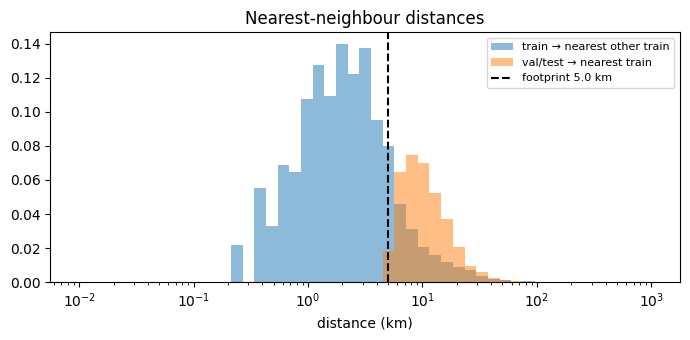

In [ ]:
# Distance histogram: cross-split nearest neighbours vs within-train nearest neighbours.
d_cross, _ = nearest_other(split_arr != "train", split_arr == "train")
d_within, _ = nearest_other(split_arr == "train", split_arr == "train", exclude_self=True)
bins = np.logspace(-2, 3, 50)
plt.figure(figsize=(7, 3.5))
plt.hist(d_within, bins=bins, alpha=0.5, density=True, label="train → nearest other train")
plt.hist(d_cross, bins=bins, alpha=0.5, density=True, label="val/test → nearest train")
plt.axvline(FOOT_KM, color="k", ls="--", label=f"footprint {FOOT_KM:.1f} km")
plt.xscale("log"); plt.xlabel("distance (km)"); plt.legend(fontsize=8); plt.title("Nearest-neighbour distances")
plt.tight_layout(); plt.savefig(OUT_DIR / "nn_distances.png", dpi=150); plt.show()

In [ ]:
# Look at the closest few cross-split pairs side by side — do they share visible pixels?
if len(overlap_pairs):
    show = overlap_pairs.nsmallest(4, "dist_km")
    fig, axes = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)), squeeze=False)
    for k, (_, r) in enumerate(show.iterrows()):
        for j, (idx, sp) in enumerate([(r.query_idx, r.query_split), (r.ref_idx, r.ref_split)]):
            row = df.loc[idx]
            axes[k, j].imshow(Image.open(ROOT / row[PATH_COL] / "images" / "visible" / "composite.png"))
            axes[k, j].set_title(f"{sp} | {row[TARGET_COL]} | {r.dist_km:.2f} km", fontsize=8); axes[k, j].axis("off")
    plt.tight_layout(); plt.savefig(OUT_DIR / "overlap_examples.png", dpi=120); plt.show()

### L4 ; near-duplicate composites (perceptual hash)
A perceptual hash turns each image into 64 bits that stay similar when the image is similar.
The Hamming distance (number of differing bits) between two hashes is small for near-duplicates.
Flag cross-split pairs with distance ≤ 6 and **inspect them visually** — the threshold is a screening tool, not proof.

In [ ]:
hashes = np.array([imagehash.phash(Image.open(ROOT / p / "images" / "visible" / "composite.png")).hash.flatten()
                   for p in df[PATH_COL]], dtype=np.uint8)              # (N, 64) bits
H = hashes.astype(np.int32)
ham = H @ (1 - H).T + (1 - H) @ H.T                                       # pairwise Hamming distances
np.fill_diagonal(ham, 99)
different_split = split_arr[:, None] != split_arr[None, :]
HAM_T = 6
ii, jj = np.where((ham <= HAM_T) & different_split & (np.arange(len(df))[:, None] < np.arange(len(df))[None, :]))
dups = pd.DataFrame({"i": ii, "j": jj, "hamming": ham[ii, jj],
                     "split_i": split_arr[ii], "split_j": split_arr[jj],
                     "label_i": df[TARGET_COL].values[ii], "label_j": df[TARGET_COL].values[jj]})
print(f"Cross-split pairs with Hamming ≤ {HAM_T}:", len(dups))
print("Distribution of each image's closest cross-split Hamming distance:")
print(pd.Series(np.where(different_split, ham, 99).min(1)).describe())
dups.to_csv(OUT_DIR / "near_duplicate_pairs.csv", index=False)
display(dups.head(10))

Cross-split pairs with Hamming ≤ 6: 0
Distribution of each image's closest cross-split Hamming distance:
count    2757.000000
mean       18.059485
std         1.564093
min        10.000000
25%        18.000000
50%        18.000000
75%        20.000000
max        22.000000
dtype: float64


,i,j,hamming,split_i,split_j,label_i,label_j


In [ ]:
if len(dups):
    show = dups.nsmallest(min(4, len(dups)), "hamming")
    fig, axes = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)), squeeze=False)
    for k, (_, r) in enumerate(show.iterrows()):
        for j, idx in enumerate([r.i, r.j]):
            row = df.loc[idx]
            axes[k, j].imshow(Image.open(ROOT / row[PATH_COL] / "images" / "visible" / "composite.png"))
            axes[k, j].set_title(f"{row['split']} | {row[TARGET_COL]} | ham={r.hamming}", fontsize=8); axes[k, j].axis("off")
    plt.tight_layout(); plt.show()

### L5 : columns / data not available at prediction time
An officer at prediction time has: the image and the loss polygon (from Global Forest Change alerts).
They do **not** have the label. Auxiliary data is excluded by design (image-only approach).


In [ ]:
print("CSV columns and their role:")
role = {TARGET_COL: "TARGET (never an input)", FINE_COL: "label detail — analysis only, never an input",
        PATH_COL: "file pointer", "latitude": "metadata — leakage checks / error analysis only",
        "longitude": "metadata — leakage checks / error analysis only",
        "year": "metadata — available at prediction time but NOT used as input (image-only)"}
for c in pd.read_csv(ROOT / "train.csv", nrows=1).columns:
    print(f"  {c:15s} -> {role.get(c, 'CHECK: role not yet decided')}")
print("\nEvents with an auxiliary folder:", int(df["has_auxiliary"].sum()), "(not loaded by any model)")

CSV columns and their role:
  label           -> label detail — analysis only, never an input
  merged_label    -> TARGET (never an input)
  latitude        -> metadata — leakage checks / error analysis only
  longitude       -> metadata — leakage checks / error analysis only
  year            -> metadata — available at prediction time but NOT used as input (image-only)
  example_path    -> file pointer

Events with an auxiliary folder: 2757 (not loaded by any model)


## 7. Decision point : keep the official split or not?  


In [ ]:
# Group events whose footprints chain together (single-linkage at FOOT_KM). Events in one group should share a split.
from scipy.sparse.csgraph import connected_components
from scipy.sparse import csr_matrix
tree = BallTree(coords, metric="haversine")
nbrs = tree.query_radius(coords, r=FOOT_KM * np.sqrt(2) / EARTH_KM)   # radius covers the square's diagonal
rows_, cols_ = [], []
for i, js in enumerate(nbrs):
    for j in js:
        if i < j and box_overlap(i, j):
            rows_.append(i); cols_.append(j)
n_groups, group_id = connected_components(csr_matrix((np.ones(len(rows_)), (rows_, cols_)), shape=(len(df),) * 2), directed=False)
df["spatial_group"] = group_id
mixed = df.groupby("spatial_group")["split"].nunique()
print(f"Spatial groups: {n_groups} | largest group size: {df['spatial_group'].value_counts().max()}")
print("Groups spanning >1 official split:", int((mixed > 1).sum()),
      "| events in those groups:", int(df["spatial_group"].isin(mixed[mixed > 1].index).sum()))

Spatial groups: 1703 | largest group size: 17
Groups spanning >1 official split: 0 | events in those groups: 0


In [ ]:
# >>> Decided after reading the results above  <<<
SPLIT_DECISION = "official"     # "official" or "spatial_grouped"
SPLIT_REASON = ("Official split kept. L1: 0 duplicated event folders; L2: 0 locations spanning splits; "
                "L3: 0 cross-split footprint overlaps (median nearest-train distance 12.8 km for val and "
                "test vs 4.9 km within train); L4: 0 near-duplicate composites (closest cross-split "
                "Hamming distance 10). Events whose footprints overlap form 1,703 groups (largest 17), "
                "and 0 groups span more than one split. The official split therefore already keeps nearby "
                "events apart, and it allows comparison with published ForestNet results.")

## 8. Freeze the split manifest and start the experiment log
Every later notebook loads `split_manifest.csv` and checks its hash, so all models use the identical split.

In [ ]:
manifest_cols = [PATH_COL, "split", TARGET_COL, FINE_COL, "latitude", "longitude"] + \
                (["year"] if "year" in df.columns else []) + \
                ["n_single_scenes", "n_infrared", "cloud_proxy", "loss_area_px2", "spatial_group"]
manifest = df[manifest_cols].sort_values(PATH_COL).reset_index(drop=True)
manifest_path = OUT_DIR.parent / "split_manifest.csv"
manifest.to_csv(manifest_path, index=False)
manifest_hash = sha256(manifest_path)

meta = {"dataset_url": URL, "zip_sha256": zip_hash, "zip_size_mb": round(zip_size_mb, 1),
        "licence": "CC BY 4.0 (stated on ForestNet project page)", "n_events": len(df),
        "has_nir_all_events": HAS_NIR, "image_px": IMG_PX, "footprint_km": round(FOOT_KM, 2),
        "split_decision": SPLIT_DECISION, "split_reason": SPLIT_REASON,
        "manifest_sha256": manifest_hash, "train_rgb_norm": train_norm, "seed": SEED,
        "created": time.strftime("%Y-%m-%d %H:%M:%S")}
with open(OUT_DIR.parent / "dataset_meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print(json.dumps(meta, indent=2))

{
  "dataset_url": "http://download.cs.stanford.edu/deep/ForestNetDataset.zip",
  "zip_sha256": "a94c6a372ba85c91336718527d552560b2e1818e6d98a51e342b60bd6b231698",
  "zip_size_mb": 3360.1,
  "licence": "CC BY 4.0 (stated on ForestNet project page)",
  "n_events": 2757,
  "has_nir_all_events": true,
  "image_px": 332,
  "footprint_km": 4.98,
  "split_decision": "official",
  "split_reason": "Official split kept. L1: 0 duplicated event folders; L2: 0 locations spanning splits; L3: 0 cross-split footprint overlaps (median nearest-train distance 12.8 km for val and test vs 4.9 km within train); L4: 0 near-duplicate composites (closest cross-split Hamming distance 10). Events whose footprints overlap form 1,703 groups (largest 17), and 0 groups span more than one split. The official split therefore already keeps nearby events apart, and it allows comparison with published ForestNet results.",
  "manifest_sha256": "c51228bf421e90c49123bd8925eb9ca1544a18f223d6c1f992237e9754e3cb8b",
  "train_r

In [ ]:
LOG_PATH = BASE / "experiment_log.csv"
LOG_COLS = ["run_id", "date", "stage", "model", "change", "hyperparameters", "seed",
            "val_macro_f1", "val_recall_plantation", "val_recall_other",
            "train_time_s", "infer_ms_per_img", "outcome", "note"]
if not LOG_PATH.exists():
    pd.DataFrame(columns=LOG_COLS).to_csv(LOG_PATH, index=False)
    print("Created", LOG_PATH)
else:
    print("Log already exists — not overwritten:", LOG_PATH)

Log already exists — not overwritten: /content/drive/MyDrive/forestnet_project/experiment_log.csv


## 9. Summary

In [ ]:
print("=== STAGE 1 SUMMARY ===")
print("Events:", len(df), "| per split:", df["split"].value_counts().to_dict())
print("Class counts (all):", df[TARGET_COL].value_counts().to_dict())
display(counts)
print("NIR present for all events:", HAS_NIR, "| infrared files per event:", df["n_infrared"].value_counts().to_dict())
print("Image sizes:", df.groupby(["img_h", "img_w"]).size().to_dict())
print("Single scenes per event: median", df["n_single_scenes"].median(), "| min", df["n_single_scenes"].min(), "| max", df["n_single_scenes"].max())
print("L1 duplicated event folders:", int(dup_paths.sum()))
print("L2 locations spanning splits:", len(cross))
display(leak_df)
print(f"L4 near-duplicate cross-split pairs (ham ≤ {HAM_T}):", len(dups))
print("Spatial groups spanning >1 split:", int((mixed > 1).sum()))
print("Manifest SHA-256:", manifest_hash)

=== STAGE 1 SUMMARY ===
Events: 2757 | per split: {'train': 1616, 'test': 668, 'val': 473}
Class counts (all): {'Plantation': 1173, 'Smallholder agriculture': 912, 'Other': 407, 'Grassland shrubland': 265}


split,train,val,test,All
merged_label,,,,
Grassland shrubland,143,45,77,265
Other,231,70,106,407
Plantation,686,218,269,1173
Smallholder agriculture,556,140,216,912
All,1616,473,668,2757


NIR present for all events: True | infrared files per event: {2: 659, 1: 550, 3: 488, 4: 341, 5: 193, 6: 148, 7: 101, 8: 90, 9: 53, 11: 39, 10: 37, 12: 13, 13: 12, 15: 9, 14: 8, 17: 5, 16: 4, 18: 2, 21: 2, 23: 1, 20: 1, 22: 1}
Image sizes: {(332, 332): 2757}
Single scenes per event: median 2.0 | min 0 | max 22
L1 duplicated event folders: 0
L2 locations spanning splits: 0


,query,reference,median_NN_km,n_within_1km,n_footprint_overlap,pct_overlap,same_label_among_overlaps_%
0,val,train,12.79,0,0.0,0.0,NaN
1,test,train,12.75,0,0.0,0.0,NaN
2,test,val,25.94,0,0.0,0.0,NaN
3,train,train (within),4.87,75,NaN,NaN,NaN
4,val,val (within),3.96,26,NaN,NaN,NaN
5,test,test (within),5.67,19,NaN,NaN,NaN


L4 near-duplicate cross-split pairs (ham ≤ 6): 0
Spatial groups spanning >1 split: 0
Manifest SHA-256: c51228bf421e90c49123bd8925eb9ca1544a18f223d6c1f992237e9754e3cb8b
